# Fine-Tuning Qwen2.5 with QLoRA: Yelp Star Rating Predictor

**Task:** read a Yelp review and predict its star rating (1-5).

**Approach:** QLoRA (4-bit quantization + LoRA adapters) on a free Kaggle T4 GPU, using the Yelp/yelp_review_full dataset. Only about 0.3-0.4% of each model's parameters are trained. Experiments on Qwen2.5-0.5B first, then the best setup on Qwen2.5-1.5B.

## Results (300 unseen test reviews)

| Model | Base | Training reviews | Accuracy ↑ | Within 1 star ↑ | MAE ↓ |
|---|---|---|---|---|---|
| Qwen2.5-0.5B (no fine-tuning) | 0.5B | - | 0.427 | 0.780 | 0.889 |
| Run 1: r=16, lr=2e-4, attention, 1 epoch | 0.5B | 2,000 | 0.590 | 0.957 | 0.467 |
| Exp A: bigger adapter (r=32) | 0.5B | 2,000 | 0.590 | 0.943 | 0.487 |
| Exp B: smaller learning rate (1e-4) | 0.5B | 2,000 | 0.580 | 0.950 | 0.497 |
| Exp C: attention + MLP layers | 0.5B | 2,000 | 0.573 | 0.947 | 0.490 |
| Exp D: 2 epochs | 0.5B | 2,000 | 0.597 | 0.960 | 0.453 |
| Exp E: 5,000 reviews | 0.5B | 5,000 | 0.607 | 0.967 | 0.440 |
| Qwen2.5-1.5B (no fine-tuning) | 1.5B | - | 0.560 | 0.927 | 0.547 |
| **Exp F: Qwen2.5-1.5B (best)** | **1.5B** | **5,000** | **0.650** | **0.983** | **0.383** |

## Key takeaways

**1.** Fine-tuning + a bigger base model improved accuracy from 42.7% to 65.0%, and predictions within 1 star from 78% to 98.3%.

**2.** Tuning the adapter (r=32), learning rate or layers (MLP) gave no gain. More training (2 epochs) and more data (5,000 reviews) gave small gains.

**3.** The biggest jump came from a smarter base model: Qwen2.5-1.5B (+4.3 points over the best 0.5B model).

**4.** Lower loss doesn't always mean higher accuracy: always check the real metrics.

## Notebook outline

**Steps 1-3:** setup, data, resume check (reload the trained adapter from Hugging Face) and confusion matrix

**Steps 4-6:** Experiments A, B and C

**Step 7:** validation and test loss for all models

**Step 8:** Experiment D (2 epochs)

**Steps 9-10:** Experiment E (5,000 reviews) and the 0.5B comparison

**Steps 11-12:** Experiment F (Qwen2.5-1.5B) and the final comparison

## Step 1: Setup

In [1]:
import os, subprocess
!mkdir -p /content
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle gives 2 GPUs; use one
try:
    gpu = subprocess.run(["nvidia-smi"], capture_output=True, text=True)
except FileNotFoundError:
    gpu = subprocess.CompletedProcess([], 1, "", "")
if gpu.returncode != 0:
    raise SystemExit("NO GPU: Runtime → Change runtime type → T4 GPU, then Run all again.")
print([l for l in gpu.stdout.splitlines() if "Tesla" in l or "T4" in l][:1] or gpu.stdout[:300])

['|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |']


In [3]:
!pip uninstall -y -q diffusers gradio gradio-client
!pip install -q bitsandbytes==0.48.2 trl==0.25.1 transformers==4.57.6 peft datasets accelerate

## Step 2: Imports, Hugging Face login, data

In [4]:
import gc, re, json, time
from collections import Counter
import numpy as np
import torch
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, set_seed
from peft import LoraConfig, PeftModel, prepare_model_for_kbit_training
from trl import SFTConfig, SFTTrainer
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from huggingface_hub import login, whoami, HfApi, create_repo

try:
    from kaggle_secrets import UserSecretsClient
    login(UserSecretsClient().get_secret("HF_TOKEN"))
except ImportError:
    from google.colab import userdata
    login(userdata.get("HF_TOKEN"))
print("HF user:", whoami()["name"], "| GPU:", torch.cuda.get_device_name(0))
HF_USER = "shivkrchy9876"
MAIN_REPO = f"{HF_USER}/review-star-rater-qlora"
api = HfApi()

BASE_MODEL = "Qwen/Qwen2.5-0.5B"
SEED = 42
TRAIN_SIZE, VALIDATION_SIZE, TEST_SIZE = 2000, 200, 300
MAX_REVIEW_CHARS, MAX_LENGTH = 600, 192
BATCH_SIZE, GRADIENT_ACCUMULATION_STEPS = 4, 4
WARMUP_RATIO, LR_SCHEDULER_TYPE, OPTIMIZER = 0.03, "cosine", "paged_adamw_32bit"
LORA_DROPOUT = 0.05
ATTENTION = ["q_proj", "k_proj", "v_proj", "o_proj"]
MLP = ["gate_proj", "up_proj", "down_proj"]
set_seed(SEED)

dataset = load_dataset("Yelp/yelp_review_full")
train_pool = dataset["train"].shuffle(seed=SEED)
train_data = train_pool.select(range(TRAIN_SIZE))
test_data = dataset["test"].shuffle(seed=SEED).select(range(TEST_SIZE))

QUESTION = "How many stars (1-5) did the reviewer give?"
def make_prompt(text):
    return f"Review: {text[:MAX_REVIEW_CHARS]}\n\n{QUESTION}\nStars:"
train_formatted = train_data.map(lambda ex: {"prompt": make_prompt(ex["text"]), "completion": f" {ex['label'] + 1}"},
                                 remove_columns=train_data.column_names)
print("Train:", len(train_formatted), "| Test:", len(test_data))

HF user: shivkrchy9876 | GPU: Tesla T4


README.md: 0.00B [00:00, ?B/s]

yelp_review_full/train-00000-of-00001.pa(…):   0%|          | 0.00/299M [00:00<?, ?B/s]

yelp_review_full/test-00000-of-00001.par(…):   0%|          | 0.00/23.5M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/650000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Train: 2000 | Test: 300


In [5]:
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
QUANT = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                           bnb_4bit_compute_dtype=torch.float32)

def load_base():
    return AutoModelForCausalLM.from_pretrained(BASE_MODEL, quantization_config=QUANT,
                                                dtype=torch.float32, device_map="auto")

def predict_stars(m, text):
    ids = tokenizer(make_prompt(text), return_tensors="pt", truncation=True, max_length=MAX_LENGTH).to(m.device)
    with torch.no_grad():
        out = m.generate(**ids, max_new_tokens=3, do_sample=False, pad_token_id=tokenizer.pad_token_id)
    m_ = re.match(r"^[1-5]", tokenizer.decode(out[0][ids["input_ids"].shape[1]:], skip_special_tokens=True).strip())
    return int(m_.group()) if m_ else None

def evaluate(m, name):
    m.eval()
    preds = [predict_stars(m, ex["text"]) for ex in test_data]
    truth = np.array([ex["label"] + 1 for ex in test_data])
    guess = np.array([p if p is not None else 3 for p in preds])
    r = {"accuracy": round(float(np.mean(guess == truth)), 3),
         "off_by_one": round(float(np.mean(np.abs(guess - truth) <= 1)), 3),
         "mae": round(float(np.mean(np.abs(guess - truth))), 3),
         "unparseable": round(sum(p is None for p in preds) / len(preds), 3)}
    print(f"RESULT model={name} accuracy={r['accuracy']:.3f} off_by_one={r['off_by_one']:.3f} "
          f"mae={r['mae']:.3f} unparseable={r['unparseable']:.3f}")
    return r, truth, guess

def free_gpu():
    for v in ["trainer", "model", "base"]:
        globals().pop(v, None)
    gc.collect(); torch.cuda.empty_cache()

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

## Step 3: Resume check: load the trained adapter from Hugging Face

In [16]:
base = load_base()
model = PeftModel.from_pretrained(base, MAIN_REPO)
run1, truth, guess = evaluate(model, "run1-r16")
print("Expected about 0.590 / 0.957 / 0.467")

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:212: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

adapter_config.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.13/dist-packages/peft/config.py:220: UserWarning: Unexpected keyword arguments ['kasa_config'] for class LoraConfig, these are ignored. This probably means that you're loading a configuration file that was saved using a higher version of the library and additional parameters have been introduced since. It is highly recommended to upgrade the PEFT version before continuing (e.g. by running `pip install -U peft`).
  warnings.warn(


adapter_model.safetensors:   0%|          | 0.00/8.68M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


RESULT model=run1-r16 accuracy=0.593 off_by_one=0.957 mae=0.463 unparseable=0.000
Expected about 0.590 / 0.957 / 0.467


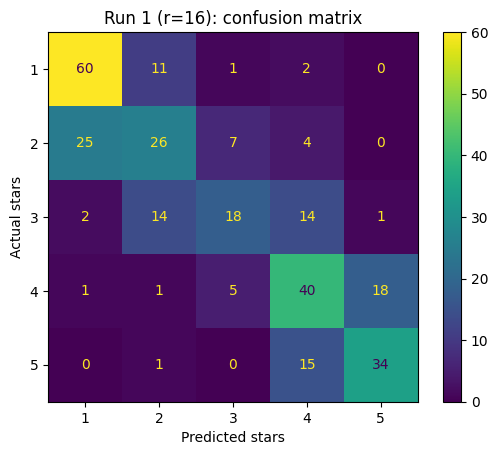

122 wrong out of 300. Five examples:

ACTUAL 3  PREDICTED 4  |  Kabuto is your run-of-the-mill Japanese Steakhouse. Different stations with chefs slinging shrimp tails around the communal dining areas like it's a lunchtime magic show. Always a plethora of laughs and gags going around the group. \n\nThis place is ...

ACTUAL 5  PREDICTED 4  |  Visiting here for 10 days and staying in a condo\nDriving around and found this place\nAte here 2x ( Lunch + Dinner)\nFood was fresh + Tasty\nSushi was great for the price\nShrimp OK but about the same as other buffets\nSesame balls were lite and gre...

ACTUAL 2  PREDICTED 1  |  Terrible terrible food...

ACTUAL 5  PREDICTED 4  |  This is a beautiful theatre with a gorgeous glass front which is great for watching the world go buy while having a coffee.\n\nI have fond memories of coming to this theatre to see the ballet since I was very young. I rather distinctly remember on my...

ACTUAL 3  PREDICTED 4  |  We stayed here the night before my girlf

In [17]:
cm = confusion_matrix(truth, guess, labels=[1, 2, 3, 4, 5])
ConfusionMatrixDisplay(cm, display_labels=[1, 2, 3, 4, 5]).plot(values_format="d")
plt.title("Run 1 (r=16): confusion matrix"); plt.xlabel("Predicted stars"); plt.ylabel("Actual stars")
plt.savefig("/content/confusion_run1.png", bbox_inches="tight"); plt.show()

wrong = [i for i in range(len(test_data)) if guess[i] != truth[i]]
print(f"{len(wrong)} wrong out of {len(test_data)}. Five examples:\n")
for i in wrong[:5]:
    print(f"ACTUAL {truth[i]}  PREDICTED {guess[i]}  |  {test_data[i]['text'][:250]}...\n")

api.upload_file(path_or_fileobj="/content/confusion_run1.png", path_in_repo="confusion_run1.png", repo_id=MAIN_REPO)
free_gpu()

## Step 4: Experiment A — bigger adapter (r=32, alpha=64)

In [20]:
free_gpu()

model_a = load_base()
model_a = prepare_model_for_kbit_training(model_a)
print("Fresh base model loaded:", BASE_MODEL)

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:212: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


Fresh base model loaded: Qwen/Qwen2.5-0.5B


LoRA config

In [21]:
lora_a = LoraConfig(
    r=32,
    lora_alpha=64,
    lora_dropout=LORA_DROPOUT,
    target_modules=ATTENTION,
    bias="none",
    task_type="CAUSAL_LM",
)
print("LoRA A:", lora_a.r, lora_a.lora_alpha, lora_a.target_modules)

LoRA A: 32 64 {'k_proj', 'v_proj', 'q_proj', 'o_proj'}


Training settings (SFTConfig)

In [27]:
OUT_A = "/kaggle/working/exp-a-r32"

cfg_a = SFTConfig(
    output_dir=OUT_A,
    num_train_epochs=1,
    per_device_train_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    learning_rate=2e-4,
    lr_scheduler_type=LR_SCHEDULER_TYPE,
    warmup_ratio=WARMUP_RATIO,
    optim=OPTIMIZER,
    max_length=MAX_LENGTH,
    completion_only_loss=True,
    logging_steps=25,
    save_strategy="steps",
    save_steps=50,
    save_total_limit=1,
    bf16=False,
    fp16=False,
    report_to="none",
    seed=SEED,
)
print("Training config ready ->", OUT_A)

Training config ready -> /kaggle/working/exp-a-r32


In [28]:
trainer_a = SFTTrainer(
    model=model_a,
    args=cfg_a,
    train_dataset=train_formatted,
    peft_config=lora_a,
    processing_class=tokenizer,
)

t0 = time.time()
trainer_a.train()
minutes_a = round((time.time() - t0) / 60, 1)
print(f"Training done in {minutes_a} min")

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss
25,0.476700
50,0.336100
75,0.312700
100,0.286500
125,0.324900


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Training done in 6.1 min


Adapter A ko Hugging Face pe save

In [29]:
REPO_A = f"{HF_USER}/review-star-rater-exp-a-r32"

trainer_a.save_model(OUT_A)
tokenizer.save_pretrained(OUT_A)

create_repo(REPO_A, private=True, exist_ok=True)
api.upload_folder(folder_path=OUT_A, repo_id=REPO_A, ignore_patterns=["checkpoint-*"])

files = api.list_repo_files(REPO_A)
assert "adapter_model.safetensors" in files, "Upload failed!"
print("✅ Adapter A saved:", f"https://huggingface.co/{REPO_A}")

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

✅ Adapter A saved: https://huggingface.co/shivkrchy9876/review-star-rater-exp-a-r32


Testing the second adaptor(r=32 , aplha=64

In [30]:
model_a_trained = trainer_a.model
model_a_trained.gradient_checkpointing_disable()
model_a_trained.config.use_cache = True

res_a, truth_a, guess_a = evaluate(model_a_trained, "exp-a-r32")

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


RESULT model=exp-a-r32 accuracy=0.590 off_by_one=0.943 mae=0.487 unparseable=0.000


Result Hugging Face pe save

In [31]:
res_a.update(r=32, alpha=64, lr=2e-4, modules="attention", minutes=minutes_a)

with open(f"{OUT_A}/results.json", "w") as f:
    json.dump(res_a, f, indent=2)
api.upload_file(path_or_fileobj=f"{OUT_A}/results.json", path_in_repo="results.json", repo_id=REPO_A)
print("✅ Results saved to", REPO_A, "->", res_a)

✅ Results saved to shivkrchy9876/review-star-rater-exp-a-r32 -> {'accuracy': 0.59, 'off_by_one': 0.943, 'mae': 0.487, 'unparseable': 0.0, 'r': 32, 'alpha': 64, 'lr': 0.0002, 'modules': 'attention', 'minutes': 6.1}


mermory release from experminet A

In [32]:
del trainer_a, model_a, model_a_trained
free_gpu()

model_b = load_base()
model_b = prepare_model_for_kbit_training(model_b)
print("Fresh base model loaded for Experiment B")

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:212: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


Fresh base model loaded for Experiment B


## Step 5: Experiment B — smaller learning rate (lr=1e-4)

LoRA config

In [33]:
lora_b = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=LORA_DROPOUT,
    target_modules=ATTENTION,
    bias="none",
    task_type="CAUSAL_LM",
)
print("LoRA B:", lora_b.r, lora_b.lora_alpha, lora_b.target_modules)

LoRA B: 16 32 {'k_proj', 'v_proj', 'q_proj', 'o_proj'}


Training settings

In [34]:
OUT_B = "/kaggle/working/exp-b-lr1e-4"

cfg_b = SFTConfig(
    output_dir=OUT_B,
    num_train_epochs=1,
    per_device_train_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    learning_rate=1e-4,
    lr_scheduler_type=LR_SCHEDULER_TYPE,
    warmup_ratio=WARMUP_RATIO,
    optim=OPTIMIZER,
    max_length=MAX_LENGTH,
    completion_only_loss=True,
    logging_steps=25,
    save_strategy="steps",
    save_steps=50,
    save_total_limit=1,
    bf16=False,
    fp16=False,
    report_to="none",
    seed=SEED,
)
print("Training config B ready -> lr =", cfg_b.learning_rate)

Training config B ready -> lr = 0.0001


Train

In [35]:
trainer_b = SFTTrainer(
    model=model_b,
    args=cfg_b,
    train_dataset=train_formatted,
    peft_config=lora_b,
    processing_class=tokenizer,
)

t0 = time.time()
trainer_b.train()
minutes_b = round((time.time() - t0) / 60, 1)
print(f"Training done in {minutes_b} min")

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss
25,0.494200
50,0.343700
75,0.319100
100,0.306700
125,0.322100


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Training done in 6.1 min


Save adapter B

In [36]:
REPO_B = f"{HF_USER}/review-star-rater-exp-b-lr1e-4"

trainer_b.save_model(OUT_B)
tokenizer.save_pretrained(OUT_B)

create_repo(REPO_B, private=True, exist_ok=True)
api.upload_folder(folder_path=OUT_B, repo_id=REPO_B, ignore_patterns=["checkpoint-*"])

files = api.list_repo_files(REPO_B)
assert "adapter_model.safetensors" in files, "Upload failed!"
print("✅ Adapter B saved:", f"https://huggingface.co/{REPO_B}")

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

✅ Adapter B saved: https://huggingface.co/shivkrchy9876/review-star-rater-exp-b-lr1e-4


creation of validation set

In [37]:
val_data = train_pool.select(range(TRAIN_SIZE, TRAIN_SIZE + VALIDATION_SIZE))
val_formatted = val_data.map(
    lambda ex: {"prompt": make_prompt(ex["text"]), "completion": f" {ex['label'] + 1}"},
    remove_columns=val_data.column_names,
)
print("Validation:", len(val_formatted), "reviews")

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Validation: 200 reviews


validation test of parameter B

In [39]:
val_trainer_b = SFTTrainer(
    model=trainer_b.model,
    args=cfg_b,
    train_dataset=train_formatted,
    eval_dataset=val_formatted,
    processing_class=tokenizer,
)

val_b = val_trainer_b.evaluate()
print(f"Experiment B  ->  validation loss = {val_b['eval_loss']:.4f}  |  last training loss = 0.3221")

Adding EOS to eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Experiment B  ->  validation loss = 0.3290  |  last training loss = 0.3221


Test B

In [125]:
from tqdm.auto import tqdm

def evaluate(m, name):
    m.eval()
    preds = [predict_stars(m, ex["text"]) for ex in tqdm(test_data, desc=f"Testing {name}")]
    truth = np.array([ex["label"] + 1 for ex in test_data])
    guess = np.array([p if p is not None else 3 for p in preds])
    r = {"accuracy": round(float(np.mean(guess == truth)), 3),
         "off_by_one": round(float(np.mean(np.abs(guess - truth) <= 1)), 3),
         "mae": round(float(np.mean(np.abs(guess - truth))), 3),
         "unparseable": round(sum(p is None for p in preds) / len(preds), 3)}
    print(f"RESULT model={name} accuracy={r['accuracy']:.3f} off_by_one={r['off_by_one']:.3f} "
          f"mae={r['mae']:.3f} unparseable={r['unparseable']:.3f}")
    return r, truth, guess

In [126]:
model_b_trained = trainer_b.model
model_b_trained.gradient_checkpointing_disable()
model_b_trained.config.use_cache = True

res_b, truth_b, guess_b = evaluate(model_b_trained, "exp-b-lr1e-4")

Testing exp-b-lr1e-4:   0%|          | 0/300 [00:00<?, ?it/s]

RESULT model=exp-b-lr1e-4 accuracy=0.580 off_by_one=0.950 mae=0.497 unparseable=0.003


Save B’s results

In [127]:
res_b.update(r=16, alpha=32, lr=1e-4, modules="attention", minutes=minutes_b,
             val_loss=round(val_b["eval_loss"], 4))

with open(f"{OUT_B}/results.json", "w") as f:
    json.dump(res_b, f, indent=2)
api.upload_file(path_or_fileobj=f"{OUT_B}/results.json", path_in_repo="results.json", repo_id=REPO_B)
print("✅ Results saved to", REPO_B, "->", res_b)

✅ Results saved to shivkrchy9876/review-star-rater-exp-b-lr1e-4 -> {'accuracy': 0.58, 'off_by_one': 0.95, 'mae': 0.497, 'unparseable': 0.003, 'r': 16, 'alpha': 32, 'lr': 0.0001, 'modules': 'attention', 'minutes': 6.1, 'val_loss': 0.329}


 ## Step 6: Experiment C — more layers (attention + MLP)

Clean memory and load a fresh model

In [128]:
del trainer_b, model_b, model_b_trained, val_trainer_b
free_gpu()

model_c = load_base()
model_c = prepare_model_for_kbit_training(model_c)
print("Fresh base model loaded for Experiment C")

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:212: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


Fresh base model loaded for Experiment C


LoRA config (the change is here: + MLP layers)

In [130]:
lora_c = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=LORA_DROPOUT,
    target_modules=ATTENTION + MLP,
    bias="none",
    task_type="CAUSAL_LM",
)
print("LoRA C:", lora_c.r, lora_c.lora_alpha, sorted(lora_c.target_modules))

LoRA C: 16 32 ['down_proj', 'gate_proj', 'k_proj', 'o_proj', 'q_proj', 'up_proj', 'v_proj']


Step 4: Training settings, now with validation during training

In [131]:
OUT_C = "/kaggle/working/exp-c-mlp"

cfg_c = SFTConfig(
    output_dir=OUT_C,
    num_train_epochs=1,
    per_device_train_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    learning_rate=2e-4,
    lr_scheduler_type=LR_SCHEDULER_TYPE,
    warmup_ratio=WARMUP_RATIO,
    optim=OPTIMIZER,
    max_length=MAX_LENGTH,
    completion_only_loss=True,
    logging_steps=25,
    eval_strategy="steps",
    eval_steps=25,
    per_device_eval_batch_size=8,
    save_strategy="steps",
    save_steps=50,
    save_total_limit=1,
    bf16=False,
    fp16=False,
    report_to="none",
    seed=SEED,
)
print("Training config C ready -> lr =", cfg_c.learning_rate, "| validation every", cfg_c.eval_steps, "steps")

Training config C ready -> lr = 0.0002 | validation every 25 steps


Step 5: Train, watching both losses

In [132]:
trainer_c = SFTTrainer(
    model=model_c,
    args=cfg_c,
    train_dataset=train_formatted,
    eval_dataset=val_formatted,
    peft_config=lora_c,
    processing_class=tokenizer,
)

t0 = time.time()
trainer_c.train()
minutes_c = round((time.time() - t0) / 60, 1)
print(f"Training done in {minutes_c} min")

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss,Validation Loss,Entropy,Num Tokens,Mean Token Accuracy
25,0.450500,0.426774,3.150929,50970.000000,0.805952
50,0.352800,0.324378,3.175471,100262.000000,0.857619
75,0.310400,0.343174,3.124294,149898.000000,0.840714
100,0.288800,0.337029,3.103574,198774.000000,0.861190
125,0.317500,0.320315,3.104269,247802.000000,0.854524


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Training done in 8.2 min


Save adapter C (

In [133]:
REPO_C = f"{HF_USER}/review-star-rater-exp-c-mlp"

trainer_c.save_model(OUT_C)
tokenizer.save_pretrained(OUT_C)

create_repo(REPO_C, private=True, exist_ok=True)
api.upload_folder(folder_path=OUT_C, repo_id=REPO_C, ignore_patterns=["checkpoint-*"])

files = api.list_repo_files(REPO_C)
assert "adapter_model.safetensors" in files, "Upload failed!"
print("✅ Adapter C saved:", f"https://huggingface.co/{REPO_C}")

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

✅ Adapter C saved: https://huggingface.co/shivkrchy9876/review-star-rater-exp-c-mlp


Test C

In [134]:
model_c_trained = trainer_c.model
model_c_trained.gradient_checkpointing_disable()
model_c_trained.config.use_cache = True

res_c, truth_c, guess_c = evaluate(model_c_trained, "exp-c-mlp")

Testing exp-c-mlp:   0%|          | 0/300 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


RESULT model=exp-c-mlp accuracy=0.573 off_by_one=0.947 mae=0.490 unparseable=0.003


Save C’s results

In [135]:
val_c = trainer_c.evaluate()
res_c.update(r=16, alpha=32, lr=2e-4, modules="attention+mlp", minutes=minutes_c,
             val_loss=round(val_c["eval_loss"], 4))

with open(f"{OUT_C}/results.json", "w") as f:
    json.dump(res_c, f, indent=2)
api.upload_file(path_or_fileobj=f"{OUT_C}/results.json", path_in_repo="results.json", repo_id=REPO_C)
print("✅ Results saved to", REPO_C, "->", res_c)

✅ Results saved to shivkrchy9876/review-star-rater-exp-c-mlp -> {'accuracy': 0.573, 'off_by_one': 0.947, 'mae': 0.49, 'unparseable': 0.003, 'r': 16, 'alpha': 32, 'lr': 0.0002, 'modules': 'attention+mlp', 'minutes': 8.2, 'val_loss': 0.3203}


 ## Step 7: Validation loss + test loss for all models (Run 1, A, B, C)

In [6]:
def to_prompt_completion(ds):
    return ds.map(
        lambda ex: {"prompt": make_prompt(ex["text"]), "completion": f" {ex['label'] + 1}"},
        remove_columns=ds.column_names,
    )

val_data = train_pool.select(range(TRAIN_SIZE, TRAIN_SIZE + VALIDATION_SIZE))
val_formatted = to_prompt_completion(val_data)
test_formatted = to_prompt_completion(test_data)
print("Validation:", len(val_formatted), "| Test:", len(test_formatted))

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

Validation: 200 | Test: 300


In [7]:
MODELS = {
    "Run 1 (r=16)":    f"{HF_USER}/review-star-rater-qlora",
    "Exp A (r=32)":    f"{HF_USER}/review-star-rater-exp-a-r32",
    "Exp B (lr=1e-4)": f"{HF_USER}/review-star-rater-exp-b-lr1e-4",
    "Exp C (+MLP)":    f"{HF_USER}/review-star-rater-exp-c-mlp",
}

loss_cfg = SFTConfig(
    output_dir="/kaggle/working/loss-check",
    per_device_eval_batch_size=8,
    max_length=MAX_LENGTH,
    completion_only_loss=True,
    bf16=False,
    fp16=False,
    report_to="none",
)

losses = {}
for name, repo in MODELS.items():
    print(f"\n=== {name}  <-  {repo}")
    model = PeftModel.from_pretrained(load_base(), repo)
    checker = SFTTrainer(
        model=model,
        args=loss_cfg,
        train_dataset=val_formatted,
        eval_dataset={"val": val_formatted, "test": test_formatted},
        processing_class=tokenizer,
    )
    out = checker.evaluate()
    losses[name] = {"val_loss": round(out["eval_val_loss"], 4), "test_loss": round(out["eval_test_loss"], 4)}
    print(name, "->", losses[name])
    del checker, model
    free_gpu()

print(f"\n{'Model':<18}{'Val loss':>10}{'Test loss':>11}")
for name, l in losses.items():
    print(f"{name:<18}{l['val_loss']:>10.4f}{l['test_loss']:>11.4f}")


=== Run 1 (r=16)  <-  shivkrchy9876/review-star-rater-qlora


config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:212: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

...

adapter_model.safetensors:   0%|          | 0.00/8.68M [00:00<?, ?B/s]

Exp B (lr=1e-4) -> {'val_loss': 0.329, 'test_loss': 0.3099}

=== Exp C (+MLP)  <-  shivkrchy9876/review-star-rater-exp-c-mlp


adapter_config.json: 0.00B [00:00, ?B/s]

adapter_model.safetensors:   0%|          | 0.00/35.2M [00:00<?, ?B/s]

Exp C (+MLP) -> {'val_loss': 0.3203, 'test_loss': 0.2977}

Model               Val loss  Test loss
Run 1 (r=16)          1.7413     1.7980
Exp A (r=32)          0.3365     0.3063
Exp B (lr=1e-4)       0.3290     0.3099
Exp C (+MLP)          0.3203     0.2977


 ## Step 8: Experiment D — more training (2 epochs) on run 1

In [8]:
free_gpu()

model_d = load_base()
model_d = prepare_model_for_kbit_training(model_d)
print("Fresh base model loaded for Experiment D")

Fresh base model loaded for Experiment D


LoRA config (same as Run 1)

In [9]:
lora_d = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=LORA_DROPOUT,
    target_modules=ATTENTION,
    bias="none",
    task_type="CAUSAL_LM",
)
print("LoRA D:", lora_d.r, lora_d.lora_alpha, sorted(lora_d.target_modules))

LoRA D: 16 32 ['k_proj', 'o_proj', 'q_proj', 'v_proj']


Training settings (the change is here: 2 epochs)

In [10]:
OUT_D = "/kaggle/working/exp-d-2epochs"

cfg_d = SFTConfig(
    output_dir=OUT_D,
    num_train_epochs=2,
    per_device_train_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    learning_rate=2e-4,
    lr_scheduler_type=LR_SCHEDULER_TYPE,
    warmup_ratio=WARMUP_RATIO,
    optim=OPTIMIZER,
    max_length=MAX_LENGTH,
    completion_only_loss=True,
    logging_steps=25,
    eval_strategy="steps",
    eval_steps=50,
    per_device_eval_batch_size=8,
    save_strategy="steps",
    save_steps=50,
    save_total_limit=1,
    bf16=False,
    fp16=False,
    report_to="none",
    seed=SEED,
)
print("Training config D ready -> epochs =", cfg_d.num_train_epochs, "| validation every", cfg_d.eval_steps, "steps")

Training config D ready -> epochs = 2 | validation every 50 steps


Train

In [11]:
trainer_d = SFTTrainer(
    model=model_d,
    args=cfg_d,
    train_dataset=train_formatted,
    eval_dataset=val_formatted,
    peft_config=lora_d,
    processing_class=tokenizer,
)

t0 = time.time()
trainer_d.train()
minutes_d = round((time.time() - t0) / 60, 1)
print(f"Training done in {minutes_d} min")

Adding EOS to train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss,Validation Loss,Entropy,Num Tokens,Mean Token Accuracy
50,0.345500,0.327645,3.056567,100262.000000,0.851190
100,0.299400,0.350449,3.045540,198774.000000,0.844048
150,0.275000,0.322067,3.058350,296748.000000,0.859286
200,0.260800,0.317521,3.050172,396827.000000,0.852619
250,0.257900,0.318043,3.048475,495604.000000,0.850952


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/pyt

Training done in 12.7 min


Save adapter D (before testing)

In [12]:
REPO_D = f"{HF_USER}/review-star-rater-exp-d-2epochs"

trainer_d.save_model(OUT_D)
tokenizer.save_pretrained(OUT_D)

create_repo(REPO_D, private=True, exist_ok=True)
api.upload_folder(folder_path=OUT_D, repo_id=REPO_D, ignore_patterns=["checkpoint-*"])

files = api.list_repo_files(REPO_D)
assert "adapter_model.safetensors" in files, "Upload failed!"
print("✅ Adapter D saved:", f"https://huggingface.co/{REPO_D}")

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

✅ Adapter D saved: https://huggingface.co/shivkrchy9876/review-star-rater-exp-d-2epochs


Test D

In [13]:
model_d_trained = trainer_d.model
model_d_trained.gradient_checkpointing_disable()
model_d_trained.config.use_cache = True

res_d, truth_d, guess_d = evaluate(model_d_trained, "exp-d-2epochs")

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


RESULT model=exp-d-2epochs accuracy=0.597 off_by_one=0.960 mae=0.453 unparseable=0.000


Save D’s results

In [14]:
res_d.update(r=16, alpha=32, lr=2e-4, modules="attention", epochs=2, minutes=minutes_d,
             val_loss=0.318)

with open(f"{OUT_D}/results.json", "w") as f:
    json.dump(res_d, f, indent=2)
api.upload_file(path_or_fileobj=f"{OUT_D}/results.json", path_in_repo="results.json", repo_id=REPO_D)
print("✅ Results saved to", REPO_D, "->", res_d)

✅ Results saved to shivkrchy9876/review-star-rater-exp-d-2epochs -> {'accuracy': 0.597, 'off_by_one': 0.96, 'mae': 0.453, 'unparseable': 0.0, 'r': 16, 'alpha': 32, 'lr': 0.0002, 'modules': 'attention', 'epochs': 2, 'minutes': 12.7, 'val_loss': 0.318}


 Experiment E — bigger training set (5,000 reviews, 2 epochs)

Create the bigger training set (no overlap with validation)

In [15]:
BIG_TRAIN_SIZE = 5000
extra = BIG_TRAIN_SIZE - TRAIN_SIZE
big_idx = list(range(0, TRAIN_SIZE)) + list(range(TRAIN_SIZE + VALIDATION_SIZE, TRAIN_SIZE + VALIDATION_SIZE + extra))

train_big = train_pool.select(big_idx)
train_big_formatted = to_prompt_completion(train_big)

val_idx = set(range(TRAIN_SIZE, TRAIN_SIZE + VALIDATION_SIZE))
print("Training reviews:", len(train_big_formatted))
print("Overlap with validation:", len(val_idx & set(big_idx)), "(must be 0)")

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Training reviews: 5000
Overlap with validation: 0 (must be 0)


 Clean memory and load a fresh base model

In [16]:
del trainer_d, model_d, model_d_trained
free_gpu()

model_e = load_base()
model_e = prepare_model_for_kbit_training(model_e)
print("Fresh base model loaded for Experiment E")

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:212: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


Fresh base model loaded for Experiment E


LoRA config (same as D)

In [17]:
lora_e = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=LORA_DROPOUT,
    target_modules=ATTENTION,
    bias="none",
    task_type="CAUSAL_LM",
)
print("LoRA E:", lora_e.r, lora_e.lora_alpha, sorted(lora_e.target_modules))

LoRA E: 16 32 ['k_proj', 'o_proj', 'q_proj', 'v_proj']


Training settings (2 epochs, like D)

Training settings (same as Experiment D: 2 epochs, lr=2e-4)

In [18]:
OUT_E = "/kaggle/working/exp-e-5k"

cfg_e = SFTConfig(
    output_dir=OUT_E,
    num_train_epochs=2,
    per_device_train_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    learning_rate=2e-4,
    lr_scheduler_type=LR_SCHEDULER_TYPE,
    warmup_ratio=WARMUP_RATIO,
    optim=OPTIMIZER,
    max_length=MAX_LENGTH,
    completion_only_loss=True,
    logging_steps=50,
    eval_strategy="steps",
    eval_steps=100,
    per_device_eval_batch_size=8,
    save_strategy="steps",
    save_steps=100,
    save_total_limit=1,
    bf16=False,
    fp16=False,
    report_to="none",
    seed=SEED,
)
print("Training config E ready -> epochs =", cfg_e.num_train_epochs, "| lr =", cfg_e.learning_rate,
      "| validation every", cfg_e.eval_steps, "steps")

Training config E ready -> epochs = 2 | lr = 0.0002 | validation every 100 steps


Train (5,000 reviews, watching training + validation loss)

In [19]:
trainer_e = SFTTrainer(
    model=model_e,
    args=cfg_e,
    train_dataset=train_big_formatted,
    eval_dataset=val_formatted,
    peft_config=lora_e,
    processing_class=tokenizer,
)

t0 = time.time()
trainer_e.train()
minutes_e = round((time.time() - t0) / 60, 1)
print(f"Training done in {minutes_e} min")

Adding EOS to train dataset:   0%|          | 0/5000 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/5000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/5000 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss,Validation Loss,Entropy,Num Tokens,Mean Token Accuracy
100,0.337200,0.359517,3.124979,201227.000000,0.837619
200,0.316400,0.320804,3.177393,397130.000000,0.854524
300,0.300500,0.307386,3.179092,597677.000000,0.856190
400,0.258300,0.310019,3.113505,797708.000000,0.869524
500,0.243000,0.305966,3.108194,997618.000000,0.872857
600,0.254700,0.302254,3.115523,1197146.000000,0.866190


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/pyt

Training done in 30.3 min


Save adapter E to Hugging Face

In [20]:
REPO_E = f"{HF_USER}/review-star-rater-exp-e-5k"

trainer_e.save_model(OUT_E)
tokenizer.save_pretrained(OUT_E)

create_repo(REPO_E, private=True, exist_ok=True)
api.upload_folder(folder_path=OUT_E, repo_id=REPO_E, ignore_patterns=["checkpoint-*"])

files = api.list_repo_files(REPO_E)
assert "adapter_model.safetensors" in files, "Upload failed!"
print("✅ Adapter E saved:", f"https://huggingface.co/{REPO_E}")

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

✅ Adapter E saved: https://huggingface.co/shivkrchy9876/review-star-rater-exp-e-5k


Test E

 Test adapter E on the 300 test reviews

In [21]:
model_e_trained = trainer_e.model
model_e_trained.gradient_checkpointing_disable()
model_e_trained.config.use_cache = True

res_e, truth_e, guess_e = evaluate(model_e_trained, "exp-e-5k")

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


RESULT model=exp-e-5k accuracy=0.607 off_by_one=0.967 mae=0.440 unparseable=0.000


### Save Experiment E's results to Hugging Face

In [22]:
res_e.update(r=16, alpha=32, lr=2e-4, modules="attention", epochs=2, train_size=BIG_TRAIN_SIZE,
             minutes=minutes_e, val_loss=0.302)

with open(f"{OUT_E}/results.json", "w") as f:
    json.dump(res_e, f, indent=2)
api.upload_file(path_or_fileobj=f"{OUT_E}/results.json", path_in_repo="results.json", repo_id=REPO_E)
print("✅ Results saved to", REPO_E, "->", res_e)

✅ Results saved to shivkrchy9876/review-star-rater-exp-e-5k -> {'accuracy': 0.607, 'off_by_one': 0.967, 'mae': 0.44, 'unparseable': 0.0, 'r': 16, 'alpha': 32, 'lr': 0.0002, 'modules': 'attention', 'epochs': 2, 'train_size': 5000, 'minutes': 30.3, 'val_loss': 0.302}


 Step 10: Final comparison of all models

In [23]:
final = {
    "Base Qwen (no training)": {"train": 0,    "epochs": 0, "r": None, "lr": None, "modules": None,            "accuracy": 0.427, "off_by_one": 0.780, "mae": 0.889, "val_loss": None},
    "Run 1":                   {"train": 2000, "epochs": 1, "r": 16,   "lr": 2e-4, "modules": "attention",     "accuracy": 0.590, "off_by_one": 0.957, "mae": 0.467, "val_loss": None},
    "Exp A (r=32)":            {"train": 2000, "epochs": 1, "r": 32,   "lr": 2e-4, "modules": "attention",     "accuracy": 0.590, "off_by_one": 0.943, "mae": 0.487, "val_loss": 0.337},
    "Exp B (lr=1e-4)":         {"train": 2000, "epochs": 1, "r": 16,   "lr": 1e-4, "modules": "attention",     "accuracy": 0.580, "off_by_one": 0.950, "mae": 0.497, "val_loss": 0.329},
    "Exp C (+MLP)":            {"train": 2000, "epochs": 1, "r": 16,   "lr": 2e-4, "modules": "attention+mlp", "accuracy": 0.573, "off_by_one": 0.947, "mae": 0.490, "val_loss": 0.320},
    "Exp D (2 epochs)":        {"train": 2000, "epochs": 2, "r": 16,   "lr": 2e-4, "modules": "attention",     "accuracy": 0.597, "off_by_one": 0.960, "mae": 0.453, "val_loss": 0.318},
    "Exp E (5k reviews)":      {"train": 5000, "epochs": 2, "r": 16,   "lr": 2e-4, "modules": "attention",     "accuracy": 0.607, "off_by_one": 0.967, "mae": 0.440, "val_loss": 0.302},
}

print(f"{'Model':<26}{'Train':>7}{'Ep':>4}{'Acc':>7}{'Off±1':>8}{'MAE':>7}{'Val loss':>10}")
for name, r in final.items():
    vl = f"{r['val_loss']:.3f}" if r["val_loss"] is not None else "-"
    print(f"{name:<26}{r['train']:>7}{r['epochs']:>4}{r['accuracy']:>7.3f}{r['off_by_one']:>8.3f}{r['mae']:>7.3f}{vl:>10}")

best = max((k for k in final if k != "Base Qwen (no training)"),
           key=lambda k: (final[k]["accuracy"], -final[k]["mae"]))
print("\n🏆 Best model:", best)

summary = {"best_model": best, "best_repo": REPO_E, "results": final,
           "note": "Run 1's validation loss is not comparable (trained in a different notebook)."}
with open("/kaggle/working/final_comparison.json", "w") as f:
    json.dump(summary, f, indent=2)
api.upload_file(path_or_fileobj="/kaggle/working/final_comparison.json",
                path_in_repo="final_comparison.json", repo_id=REPO_E)
print("✅ Final comparison saved to", REPO_E)

Model                       Train  Ep    Acc   Off±1    MAE  Val loss
Base Qwen (no training)         0   0  0.427   0.780  0.889         -
Run 1                        2000   1  0.590   0.957  0.467         -
Exp A (r=32)                 2000   1  0.590   0.943  0.487     0.337
Exp B (lr=1e-4)              2000   1  0.580   0.950  0.497     0.329
Exp C (+MLP)                 2000   1  0.573   0.947  0.490     0.320
Exp D (2 epochs)             2000   2  0.597   0.960  0.453     0.318
Exp E (5k reviews)           5000   2  0.607   0.967  0.440     0.302

🏆 Best model: Exp E (5k reviews)
✅ Final comparison saved to shivkrchy9876/review-star-rater-exp-e-5k


baseline test of the 1.5B model

 Experiment F — bigger base model (Qwen2.5-1.5B)

### Baseline: test Qwen2.5-1.5B before any training

In [24]:
del trainer_e, model_e, model_e_trained
free_gpu()

BASE_MODEL = "Qwen/Qwen2.5-1.5B"
base_f = load_base()
print("Loaded", BASE_MODEL, "| GPU memory:", round(base_f.get_memory_footprint() / 1e9, 2), "GB")

res_base_f, _, _ = evaluate(base_f, "base-1.5B")

config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:212: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Loaded Qwen/Qwen2.5-1.5B | GPU memory: 1.59 GB
RESULT model=base-1.5B accuracy=0.560 off_by_one=0.927 mae=0.547 unparseable=0.000


### Prepare the 1.5B model for training + LoRA config (same as E)

In [25]:
model_f = prepare_model_for_kbit_training(base_f)

lora_f = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=LORA_DROPOUT,
    target_modules=ATTENTION,
    bias="none",
    task_type="CAUSAL_LM",
)
print("Model F ready:", BASE_MODEL, "| LoRA F:", lora_f.r, lora_f.lora_alpha, sorted(lora_f.target_modules))

Model F ready: Qwen/Qwen2.5-1.5B | LoRA F: 16 32 ['k_proj', 'o_proj', 'q_proj', 'v_proj']


### Training settings (same as Experiment E: 2 epochs, lr=2e-4)

In [30]:
OUT_F = "/kaggle/working/exp-f-1.5b"

cfg_f = SFTConfig(
    output_dir=OUT_F,
    num_train_epochs=2,
    per_device_train_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    learning_rate=2e-4,
    lr_scheduler_type=LR_SCHEDULER_TYPE,
    warmup_ratio=WARMUP_RATIO,
    optim=OPTIMIZER,
    max_length=MAX_LENGTH,
    completion_only_loss=True,
    logging_steps=50,
    eval_strategy="steps",
    eval_steps=100,
    per_device_eval_batch_size=8,
    save_strategy="steps",
    save_steps=100,
    save_total_limit=1,
    bf16=False,
    fp16=False,
    report_to="none",
    seed=SEED,
)
print("Training config F ready ->", BASE_MODEL, "| epochs =", cfg_f.num_train_epochs, "| lr =", cfg_f.learning_rate)

Training config F ready -> Qwen/Qwen2.5-1.5B | epochs = 2 | lr = 0.0002


### Train the 1.5B model (5,000 reviews, watching training + validation loss)

In [31]:
trainer_f = SFTTrainer(
    model=model_f,
    args=cfg_f,
    train_dataset=train_big_formatted,
    eval_dataset=val_formatted,
    peft_config=lora_f,
    processing_class=tokenizer,
)
trainer_f.model.print_trainable_parameters()

t0 = time.time()
trainer_f.train()
minutes_f = round((time.time() - t0) / 60, 1)
print(f"Training done in {minutes_f} min")

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


trainable params: 4,358,144 || all params: 1,548,072,448 || trainable%: 0.2815


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss,Validation Loss,Entropy,Num Tokens,Mean Token Accuracy
100,0.283200,0.296882,3.010456,201227.000000,0.867857
200,0.275200,0.283850,2.985579,397130.000000,0.877619
300,0.267200,0.272812,2.983904,597677.000000,0.872619
400,0.229000,0.277038,2.953481,797708.000000,0.884286
500,0.218000,0.275043,2.943788,997618.000000,0.887619
600,0.223800,0.271398,2.950048,1197146.000000,0.880952


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/pyt

Training done in 88.9 min


### Save adapter F to Hugging Face (before testing)

In [32]:
REPO_F = f"{HF_USER}/review-star-rater-exp-f-1.5b"

trainer_f.save_model(OUT_F)
tokenizer.save_pretrained(OUT_F)

create_repo(REPO_F, private=True, exist_ok=True)
api.upload_folder(folder_path=OUT_F, repo_id=REPO_F, ignore_patterns=["checkpoint-*"])

files = api.list_repo_files(REPO_F)
assert "adapter_model.safetensors" in files, "Upload failed!"
print("✅ Adapter F saved:", f"https://huggingface.co/{REPO_F}")

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

✅ Adapter F saved: https://huggingface.co/shivkrchy9876/review-star-rater-exp-f-1.5b


### Test adapter F on the 300 test reviews

In [33]:
model_f_trained = trainer_f.model
model_f_trained.gradient_checkpointing_disable()
model_f_trained.config.use_cache = True

res_f, truth_f, guess_f = evaluate(model_f_trained, "exp-f-1.5b")

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


RESULT model=exp-f-1.5b accuracy=0.650 off_by_one=0.983 mae=0.383 unparseable=0.000


### Save Experiment F's results to Hugging Face

In [34]:
res_f.update(base_model=BASE_MODEL, r=16, alpha=32, lr=2e-4, modules="attention", epochs=2,
             train_size=BIG_TRAIN_SIZE, minutes=minutes_f, val_loss=0.271,
             base_untrained={"accuracy": 0.560, "off_by_one": 0.927, "mae": 0.547})

with open(f"{OUT_F}/results.json", "w") as f:
    json.dump(res_f, f, indent=2)
api.upload_file(path_or_fileobj=f"{OUT_F}/results.json", path_in_repo="results.json", repo_id=REPO_F)
print("✅ Results saved to", REPO_F, "->", res_f)

✅ Results saved to shivkrchy9876/review-star-rater-exp-f-1.5b -> {'accuracy': 0.65, 'off_by_one': 0.983, 'mae': 0.383, 'unparseable': 0.0, 'base_model': 'Qwen/Qwen2.5-1.5B', 'r': 16, 'alpha': 32, 'lr': 0.0002, 'modules': 'attention', 'epochs': 2, 'train_size': 5000, 'minutes': 88.9, 'val_loss': 0.271, 'base_untrained': {'accuracy': 0.56, 'off_by_one': 0.927, 'mae': 0.547}}


## Step 12: Final comparison of all models (including 1.5B)

In [35]:
final["Qwen2.5-1.5B base (no training)"] = {"train": 0, "epochs": 0, "r": None, "lr": None, "modules": None,
                                            "accuracy": 0.560, "off_by_one": 0.927, "mae": 0.547, "val_loss": None}
final["Exp F (1.5B, 5k reviews)"] = {"train": 5000, "epochs": 2, "r": 16, "lr": 2e-4, "modules": "attention",
                                    "accuracy": 0.650, "off_by_one": 0.983, "mae": 0.383, "val_loss": 0.271}
for name in final:
    final[name]["base"] = "1.5B" if ("1.5B" in name) else "0.5B"

print(f"{'Model':<34}{'Base':>6}{'Train':>7}{'Ep':>4}{'Acc':>7}{'Off±1':>8}{'MAE':>7}{'Val loss':>10}")
for name, r in final.items():
    vl = f"{r['val_loss']:.3f}" if r["val_loss"] is not None else "-"
    print(f"{name:<34}{r['base']:>6}{r['train']:>7}{r['epochs']:>4}{r['accuracy']:>7.3f}"
          f"{r['off_by_one']:>8.3f}{r['mae']:>7.3f}{vl:>10}")

trained = [k for k in final if final[k]["train"] > 0]
best = max(trained, key=lambda k: (final[k]["accuracy"], -final[k]["mae"]))
print("\n🏆 Best model:", best)

summary = {"best_model": best, "best_repo": REPO_F, "results": final,
           "note": "Run 1's validation loss is not comparable (trained in a different notebook)."}
with open("/kaggle/working/final_comparison.json", "w") as f:
    json.dump(summary, f, indent=2)
api.upload_file(path_or_fileobj="/kaggle/working/final_comparison.json",
                path_in_repo="final_comparison.json", repo_id=REPO_F)
print("✅ Final comparison saved to", REPO_F)

Model                               Base  Train  Ep    Acc   Off±1    MAE  Val loss
Base Qwen (no training)             0.5B      0   0  0.427   0.780  0.889         -
Run 1                               0.5B   2000   1  0.590   0.957  0.467         -
Exp A (r=32)                        0.5B   2000   1  0.590   0.943  0.487     0.337
Exp B (lr=1e-4)                     0.5B   2000   1  0.580   0.950  0.497     0.329
Exp C (+MLP)                        0.5B   2000   1  0.573   0.947  0.490     0.320
Exp D (2 epochs)                    0.5B   2000   2  0.597   0.960  0.453     0.318
Exp E (5k reviews)                  0.5B   5000   2  0.607   0.967  0.440     0.302
Qwen2.5-1.5B base (no training)     1.5B      0   0  0.560   0.927  0.547         -
Exp F (1.5B, 5k reviews)            1.5B   5000   2  0.650   0.983  0.383     0.271

🏆 Best model: Exp F (1.5B, 5k reviews)
✅ Final comparison saved to shivkrchy9876/review-star-rater-exp-f-1.5b
